# Phase 5 — Strategy rules and the backtest engine

**Goal.** A backtester you can trust, built and verified with the baseline rule before any fancier forecast touches it. The baseline is the papers' rule: size = $c_t$ / last month's realized variance.

**No peeking.** Every result in this notebook comes from **simulated** data. The engine runs on the real panel only once, at the end, for mechanical checks: dates, bounds and look-ahead. No return statistic is shown. Real-data strategy results are first read in Phase 6, where Scorecard B needs them. The 2019+ holdout is never loaded.

### Key findings

1. **The engine passes all five checks of the plan.** It finds alpha where theory says alpha exists and none where it does not. A constant forecast reproduces buy-and-hold exactly. Random timing earns nothing. A perfect forecast beats the baseline. Five months recomputed by hand in a spreadsheet match to 2 × 10⁻¹⁴.
2. **Two worlds (check 1).** On 500 simulated years with constant expected return (world A), inverse-variance timing earns α = +1.95% a year (t 6.0). With expected return proportional to variance (world B), it earns +0.13% (t 0.4), and timing *lowers* the Sharpe ratio (0.38 to 0.32). All three timing rules show the same pattern.
3. **Theory's ranking of the rules shows up.** Over 100 simulated 90-year histories, inverse variance has the largest Sharpe gain most often when μ is constant (54%), and inverse volatility when μ moves with σ (52%). When μ moves with σ², inverse variance, the rule that leans hardest, loses the most (−0.08 Sharpe on average).
4. **The primary test has little power, and the holdout has less.** The primary test is one-sided at 5% on the Sharpe gain over buy-and-hold (PREREGISTRATION Entry 3). In world A, where the edge exists by construction, it rejects in only 30% of 90-year histories; the alpha t-test rejects in 70%. Its minimum detectable effect at 80% power is a Sharpe gain of 0.18 a year, twice world A's true gain of 0.09. The primary rule is also the hardest to test: inverse variance's minimum detectable effect (0.18) is half again the volatility rules' (0.11–0.12). On a window as long as the holdout (92 months), the test rejects in 10% of world-A histories, its minimum detectable effect is 0.46, and 83% of readings are "inconclusive". The engine checks use 500 years for this reason.
5. **Constant forecast (check 2).** With the real-time $c_t$, the size is exactly 1 in every month, and the timed account matches buy-and-hold to 4 × 10⁻¹⁶. With a fixed $c$ giving size 0.7, timed = 0.7 × buy-and-hold: α of order 10⁻¹⁶, β = 0.7, R² = 1.
6. **Shuffled forecast (check 3).** 1,000 forecasts reordered in time earn a mean alpha of +0.002% a year (spread 0.30%). In world A the real forecast beats all 1,000 and passes the placebo rule. In world B it beats 67% and fails it, as it should.
7. **Oracle (check 4).** Knowing next month's variance adds only +0.02 Sharpe over the baseline in the GARCH world A. Last month's variance already tracks a smooth, persistent variance closely. In a world where each month's variance is drawn fresh, the baseline earns nothing (its Sharpe *falls*, 0.37 to 0.32) and the oracle jumps +0.23. So the oracle measures how much forecasting is left to win, and on real data (Phase 6) it will say which kind of world the market is.
8. **Hand check (check 5).** Seventy numbers at five months match a spreadsheet that rebuilds every step with plain formulas. Seven planted bugs each break the match by at least 4 × 10⁻⁴: c_t one pair early, no one-month lag, drift ignored, trading a day late, January sized on the old recipe, financing dropped, and c_t needing 7 pairs instead of 6.
9. **Real-time $c_t$ and the cap change results, as the plan warns.** With a fixed $c$ and no cap, doubling $c$ leaves the Sharpe ratio unchanged (0.530 both times). With the 1.5× cap, it does not (0.566 against 0.589). The real-time $c_t$ starts 45% above its full-sample value and takes decades to settle. The uncapped size exceeds 1.5× in 25–30% of months.
10. **Costs, on world A traded like SPY (mechanics only).** Inverse variance turns the account over 3.3 times a year and pays 0.17% a year to trade and 0.10% to borrow. Its break-even cost is 0.27% one-way (0.53% round trip), five times the 5 bp assumed for SPY. Inverse volatility trades less (2.4 times a year), so its break-even is higher (0.48% one-way), as Wang and Yan argue.

### How to read this notebook

Each check has the same parts: **what and why**, the **rule** (the pass condition; where a detail was set after a pilot run on simulated data, the section says so), the **result**, and what it **means**. Numbers quoted in the text refer to the build of 2026-10-18. The tables and plots are recomputed every time the notebook runs.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from src import engine as e
from src import variance as v
from src.engine import evaluation as ev, execution as ex, forecast as fc, handcheck as hc, synthetic as syn, weights as wt

pd.set_option("display.float_format", "{:,.4f}".format, "display.max_columns", 30, "display.width", 200,
              "display.max_colwidth", None)

RULE_NAMES = {"inv_var": "Inverse variance", "inv_vol": "Inverse volatility", "down_vol": "Downside inverse vol"}
WORLD_NAMES = {"flat": "A: μ constant", "var": "B: μ ∝ σ²", "vol": "C: μ ∝ σ"}
COLORS = {"inv_var": "#2a78d6", "inv_vol": "#eda100", "down_vol": "#4a3aa7"}        # Phase 2-4's first three hues
LIGHT, DARK, FAIL = "#86b6ef", "#1c5cab", "#e8e7e1"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})

YEARS = 500                                             # one long history per world (chosen for power, Section 4)
def world(name, years=YEARS, seed=0):
    d = syn.garch(years=years, world=name, seed=seed)
    return e.Book.single(d["x"], d["rf"])

def row(res):
    sp = ev.spanning(res["excess"], res["bench_excess"])
    return {"alpha": sp["alpha"], "t_alpha": sp["t_alpha"], "beta": sp["beta"],
            "Sharpe: buy-and-hold": ev.sharpe(res["bench_excess"]), "Sharpe: timed": ev.sharpe(res["excess"]),
            "Sharpe gain": ev.sharpe(res["excess"]) - ev.sharpe(res["bench_excess"]),
            "mean size": res["size"].mean(), "months capped": res["capped"].mean()}


## 1. The rules

### Three timing rules

| Rule | Size | If volatility doubles | Source |
|---|---|---|---|
| **Inverse variance** (primary) | $w_t = c_t / \hat\sigma_t^2$ | falls to 1/4 | Moreira and Muir (2017) |
| Inverse volatility | $w_t = c_t / \hat\sigma_t$ (the paper uses a fixed 12% target) | falls to 1/2 | Barroso and Santa-Clara (2015) |
| Downside inverse volatility | $w_t = c_t / \hat\sigma_t^-$, with $\hat\sigma_t^- = \sqrt{RV_t^-}$ | reacts to bad days only | Wang and Yan (2021) |

**Why test more than one.** The best weight for a mean-variance investor is $w_t^* = \mu_t / (\gamma \sigma_t^2)$. Which rule is best depends on how the expected return $\mu_t$ moves with risk:

- $\mu_t$ flat: $w^* \propto 1/\sigma_t^2$, so **inverse variance** is optimal.
- $\mu_t = k\sigma_t$: $w^* = k\sigma_t/(\gamma\sigma_t^2) = k/(\gamma\sigma_t)$, so **inverse volatility** is optimal.
- $\mu_t = k\sigma_t^2$: $w^* = k/\gamma$, a constant. **No timing gain.**

Wang and Yan prefer volatility scaling because its weights are less extreme and it trades less. The primary test still uses inverse variance, the papers' baseline. Until Phase 6 chooses a model, $\hat\sigma_t^2$ is last month's realized variance $RV_t$, and $\hat\sigma_t^-$ comes from last month's down days (Phase 2's downside RV).

**Two names that sound alike.** The *timing* rules above set the size of the whole mix. Phase 4's *mix* weights (equal, inverse variance, inverse volatility, shrunk mean-variance) set the ratio between the assets inside the mix. The primary uses inverse-volatility *mix* weights and inverse-variance *timing*.

### Setting $c_t$ in real time

$c_t$ is chosen so that the timed strategy's past volatility matches buy-and-hold's, using only months up to $t$:

$$c_t = \frac{\widehat{\mathrm{sd}}_{\le t}\left(r_{s+1}\right)}{\widehat{\mathrm{sd}}_{\le t}\left(r_{s+1}\cdot \text{signal}_s\right)}, \qquad \text{signal}_s = 1/\hat\sigma_s^2,\ 1/\hat\sigma_s \text{ or } 1/\hat\sigma_s^- .$$

A pair (signal$_s$, $r_{s+1}$) is complete at the end of month $s+1$, so $c_t$ uses pairs with $s+1 \le t$. It needs 120 of them, or 36 on the ETF track (Phase 7's three-year rule). MTUM starts in 2013, so 120 would leave the ETF track untimed until 2023. 36 is safe because $c_t$ only sets the average size, and the Sharpe ratio ignores size. Every rule then carries about the same risk as buy-and-hold, so the comparison is fair. Barroso and Santa-Clara's fixed 12% target is kept only to replicate their momentum result (`weights.target_c(0.12)`).

- **Why real time.** Moreira and Muir set $c$ on the full sample, which quietly uses future data. Real-time estimation is exactly where Cederburg et al. (2020) find the gains leak away.
- **Why it matters.** With a fixed $c$ and no cap, the Sharpe ratio ignores $c$. In real time, $c_t$ drifts and meets the cap, so it changes results (Section 9 shows both).
- **The mix you will hold.** $c_t$ and the forecast are computed on the mix that will be held next month, applied to all past data. When the recipe changes at a year-end, January's size uses December's returns under the new recipe, as in Phase 4.

### Leverage cap, costs, timing

| Item | Rule |
|---|---|
| Cap | $0 \le w_t \le 1.5$ in the primary test. Phase 8 tries 1.0 and 2.0. In very calm spells $\hat\sigma_t^2$ gets tiny and $w_t$ explodes; brokers cap margin, so uncapped backtests are fantasy |
| Timing | The size decided at the close of month $t$'s last trading day is traded at that close and held through month $t+1$. `delay=1` trades a day later (for Phase 8) |
| Drift | Between trades positions drift: $\tilde w_t = w_{t-1}\,(1+R_t)/(1+R_{p,t})$, with $R_{p,t} = w_{t-1}R_t + (1-w_{t-1})R^f_t$ |
| Trading cost | $\kappa \times |w_t - \tilde w_t|$ per rebalance, paid when the new position goes on. κ = 5 bp for SPY and 10 bp for factor ETFs. The account starts in cash, so the entry trade is paid too |
| Borrowing | When $w_t > 1$, the borrowed part pays the risk-free rate plus 0.5% a year |
| Short fee | The SPY short behind the hedged MTUM tilt pays 0.25% a year in the base case (SPY is easy to borrow; a choice, not a quote). Phase 8's cost row stress-tests 1% a year, for a low or missing short rebate (`COSTS["etf_short_stress"]`) |
| Paper factors | Before costs: the French and AQR factors are not tradeable as built, so their results are an upper bound |
| Break-even | Two kinds, both reported: the one-way κ that erases the Sharpe gain, and the κ that wipes out each strategy's profit (Section 10). A round trip is 2κ. Neither is compared with Barroso and Santa-Clara's 1.27 and 1.75 points |
| Benchmark | The same book at a constant size of 1, traded on the same dates and paying the same costs. The two runs differ only in the size |
| Placebo rule | The real alpha must beat 95% of the alphas from 1,000 forecasts shuffled in time. Applied to real data from Phase 6 |
| Primary test | The Sharpe gain over buy-and-hold, one-sided at 5% (Ledoit-Wolf delta method, Newey-West 6 lags). Three readings fixed in advance: **edge** if the test rejects; **no meaningful edge** if the one-sided 95% upper bound of the gain is below 0.10 a year; **inconclusive** otherwise. The minimum detectable effect at 80% power is reported with it |
| Reporting | Realized volatility of both runs beside every Sharpe ratio, so a gap in a certainty-equivalent return cannot hide a gap in size; and the average size, so costs inside each factor can be judged |

In [2]:
display(pd.DataFrame({"value": e.ENGINE_RULES}).astype(str))
display(pd.DataFrame({r: {"forecaster": f.__name__, "power": p, "size": f"c_t / σ̂^{2 * p:g}"} for r, (f, p) in e.TIMING.items()}).T)
costs = pd.DataFrame({t: {"κ per unit traded (one-way)": ", ".join(f"{k} {x * 1e4:.0f} bp" for k, x in c.kappa.items()) or "none",
                          "borrow spread a year": f"{c.borrow_spread:.2%}",
                          "short fee a year": ", ".join(f"{k} {x:.2%}" for k, x in c.short_fee.items()) or "none"}
                      for t, c in ex.COSTS.items()}).T
display(costs)


,value
rule,inv_var
max_size,1.5
min_months,120
etf_min_months,36
c_window,None
delay,0
target_vol,0.12
placebo_draws,1000
placebo_share,0.95


,forecaster,power,size
inv_var,last_rv,1.0000,c_t / σ̂^2
inv_vol,last_rv,0.5000,c_t / σ̂^1
down_vol,last_rv_down,0.5000,c_t / σ̂^1


,κ per unit traded (one-way),borrow spread a year,short fee a year
paper,none,0.00%,none
etf,"spy 5 bp, mtum 10 bp, qual 10 bp, usmv 10 bp",0.50%,spy 0.25%
etf_short_stress,"spy 5 bp, mtum 10 bp, qual 10 bp, usmv 10 bp",0.50%,spy 1.00%


## 2. The engine: five stages

```
Data  ->  Forecast  ->  Weights  ->  Execution (lag, cap, costs)  ->  Evaluation
```

| Stage | Module | Takes | Gives | Tested alone in `test/test_engine.py` |
|---|---|---|---|---|
| Data | `src/engine/data.py` | daily excess returns, rf, positions per holding month | the mix's daily return and its monthly table (exact excess return, RV, downside RV) | compounding, recipe grouping, mix on common days, Phase 4 bridge |
| Forecast | `src/engine/forecast.py` | the mix's daily returns | next month's variance, forecast at each month-end | each forecaster measures what it says; none sees past its month (except the oracle, which says so) |
| Weights | `src/engine/weights.py` | forecast, monthly returns | signal, real-time $c_t$, capped size | $c_t$ against a brute-force loop; never uses the month after; cap and floor |
| Execution | `src/engine/execution.py` | target positions, cost model | net and excess returns, turnover, drift, costs | the plan's drift and cost formulas; borrowing and short fees from the daily data; refuses gaps and missing returns |
| Evaluation | `src/engine/evaluation.py` | the monthly output | Sharpe, the primary test, spanning α, break-even κ, placebo share | known α and β recovered; the test's error matches the normal formula and rejects 5% under the null; break-even equalises the Sharpe ratios |

`src/engine/__init__.py` chains them: `run(book, rule)` gives one row per holding month, and `placebo(book, rule)` reruns weights and execution 1,000 times with the forecast shuffled. A new forecast model is any function from daily returns to a monthly series, passed as `forecaster`; nothing downstream changes (`test_a_new_forecaster_plugs_in_and_nothing_else_changes`).

**What is known when.** Row $m$ of the output is a holding month. Its forecast, signal, $c$ and size were all made at the close of month $m-1$. Its returns are earned during month $m$. That one-month lag is the place indexing bugs hide, which is why the hand check (Section 8) and a look-ahead test exist.

**Two changes from Phase 4**, both set by the plan:

- $c$ was a variance match over each recipe's 10-year window, set once a year. It is now the real-time $c_t$ above, updated monthly from all months so far.
- Phase 4 multiplied each day's return by the month's size, which assumes daily rebalancing to a constant exposure. The engine buys at the month-end close and lets the position drift, as the plan's cost formula requires. Monthly returns are exact excess returns: compounded total return minus compounded risk-free return.

So the engine will not reproduce Phase 4's timed Sharpe ratios exactly. The rule numbers and the cost model are shown below.

## 3. The simulated worlds

**What and why.** An engine can only be checked against a world whose answer is known. Each world simulates daily excess returns $x_d = \mu_d + \sigma_d z_d$, with $\sigma_d^2$ from a GARCH(1,1), $\sigma_d^2 = \omega + a\,\varepsilon_{d-1}^2 + b\,\sigma_{d-1}^2$. All worlds share the same shocks $z_d$, so they share the same variance path, and they differ only in how the expected return moves with that variance (`src/engine/synthetic.py`):

| World | Expected return | Best weight | Theory says |
|---|---|---|---|
| **A** | $\mu$ constant | $\propto 1/\sigma^2$ | inverse-variance timing earns alpha |
| **B** | $\mu \propto \sigma^2$ | constant | no timing gain: alpha zero, and timing lowers the Sharpe ratio |
| C (information) | $\mu \propto \sigma$ | $\propto 1/\sigma$ | inverse volatility is the best rule |

Each world has the same 6% average expected return, 16% long-run volatility and 2% risk-free rate. The GARCH parameters ($a = 0.10$, $b = 0.89$) bring the simulated market's monthly variance close to the real market's in Phase 2 (table below). The real market is wilder still: its variance of variance is higher and its spikes are larger.

**Why world B gives zero alpha, not negative.** The spanning regression of the timed return on buy-and-hold has $\alpha = E[w_t\mu_{t+1}] - \beta E[\mu_{t+1}]$. In world B, $\mu_{t+1} = k\,\sigma_{t+1}^2$, and to first order $\beta = E[w_t\sigma^2_{t+1}]/E[\sigma^2]$, so the two terms cancel for *any* size known in advance. What timing does lose in world B is Sharpe ratio: it adds risk that earns nothing.

,sd of log RV,AR(1) of RV,AR(1) of log RV,wildest / median RV,volatility a year
"real market, 1926-2018 (Phase 2)",1.0392,0.6204,0.7356,52.4404,0.1845
"simulated, 500 years",0.8286,0.7175,0.7026,43.5710,0.1557
"simulated, 90 years",0.8053,0.7863,0.6961,31.2959,0.1481


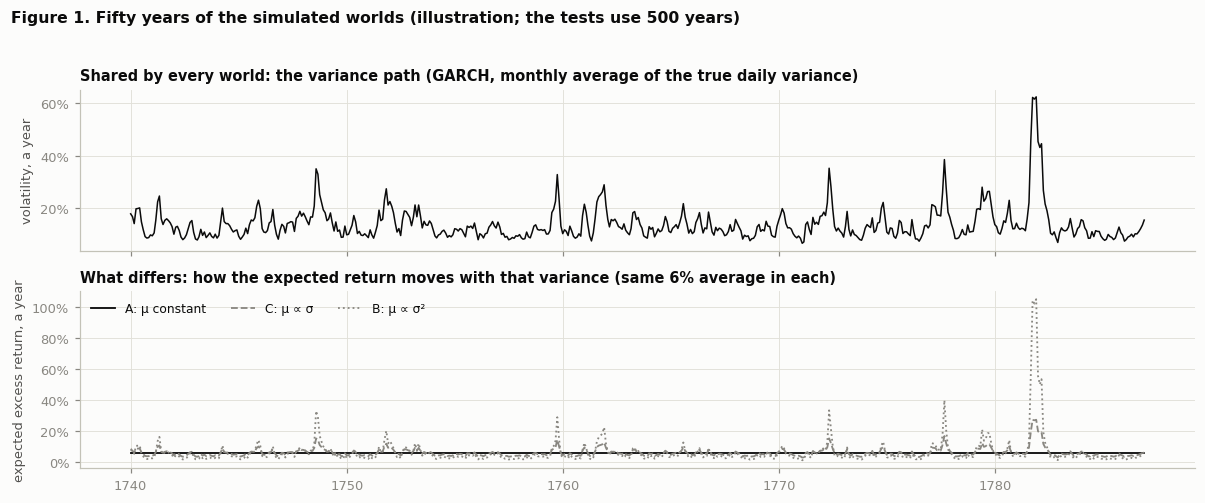

In [3]:
d = {w: syn.garch(years=90, world=w, seed=0) for w in syn.WORLDS}
mon_sigma = np.sqrt(d["flat"]["sigma2"].groupby(d["flat"].index.to_period("M")).mean() * 252)
span = slice("1740-01", "1789-12")

fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"height_ratios": [1, 1.1]})
ax = axes[0]
ax.plot(mon_sigma.loc[span].index.to_timestamp(), mon_sigma.loc[span], color=INK, lw=1.0)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylabel("volatility, a year")
ax.set_title("Shared by every world: the variance path (GARCH, monthly average of the true daily variance)")
ax = axes[1]
for w, ls in (("flat", "-"), ("vol", "--"), ("var", ":")):
    mu = (d[w]["mu"].groupby(d[w].index.to_period("M")).mean() * 252).loc[span]
    ax.plot(mu.index.to_timestamp(), mu, color=INK if w == "flat" else MUTED, ls=ls, lw=1.2, label=WORLD_NAMES[w])
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylabel("expected excess return, a year")
ax.set_title("What differs: how the expected return moves with that variance (same 6% average in each)")
ax.legend(loc="upper left", ncol=3, fontsize=8)
fig.suptitle("Figure 1. Fifty years of the simulated worlds (illustration; the tests use 500 years)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))

from src.data.load import load_dev
def rv_stats(r):
    m = v.monthly_table(r.dropna())
    return {"sd of log RV": m["log_rv"].std(), "AR(1) of RV": m["rv"].autocorr(), "AR(1) of log RV": m["log_rv"].autocorr(),
            "wildest / median RV": m["rv"].max() / m["rv"].median(), "volatility a year": m["ret"].std() * np.sqrt(12)}
calib = pd.DataFrame({"real market, 1926-2018 (Phase 2)": rv_stats(load_dev()["mkt"]),
                      "simulated, 500 years": rv_stats(syn.garch(years=YEARS, seed=0)["x"]),
                      "simulated, 90 years": rv_stats(d["flat"]["x"])}).T
display(calib)


## 4. Check 1 — Two worlds

**What and why.** It proves the engine finds the edge only where theory says it exists.

**Rule (the plan's).** With inverse-variance timing on one 500-year history per world (seed 0, costs off, the 1.5× cap): in world A, α > 0 with t > 1.96; in world B, t < 1.96. 500 years, because the Monte Carlo below shows that 90 years often miss a true edge. World C and the other two rules are reported, not judged.

In [4]:
runs = {(w, r): e.run(world(w), r) for w in syn.WORLDS for r in e.TIMING}
tab = pd.DataFrame({(WORLD_NAMES[w], RULE_NAMES[r]): row(res) for (w, r), res in runs.items()}).T
tab.index.names = ["world", "timing rule"]
display(tab.style.format({"alpha": "{:+.2%}", "t_alpha": "{:+.2f}", "beta": "{:.2f}", "Sharpe: buy-and-hold": "{:.3f}",
                          "Sharpe: timed": "{:.3f}", "Sharpe gain": "{:+.3f}", "mean size": "{:.2f}", "months capped": "{:.0%}"})
        .apply(lambda r: ["font-weight: bold"] * len(r) if r.name[1] == RULE_NAMES["inv_var"] and r.name[0] != WORLD_NAMES["vol"] else [""] * len(r), axis=1))
a, b = tab.loc[(WORLD_NAMES["flat"], RULE_NAMES["inv_var"])], tab.loc[(WORLD_NAMES["var"], RULE_NAMES["inv_var"])]
print(f"CHECK 1 (inverse variance, {YEARS} years): world A alpha {a['alpha']:+.2%} (t {a['t_alpha']:.2f}) -> "
      f"{'pass' if a['alpha'] > 0 and a['t_alpha'] > 1.96 else 'FAIL'};  world B t {b['t_alpha']:.2f} -> {'pass' if b['t_alpha'] < 1.96 else 'FAIL'}")


CHECK 1 (inverse variance, 500 years): world A alpha +1.95% (t 6.00) -> pass;  world B t 0.40 -> pass


**Result: pass.** World A: α = +1.95% a year with t = 6.0, and the Sharpe ratio rises from 0.39 to 0.47. World B: α = +0.13% with t = 0.4, and the Sharpe ratio *falls* from 0.38 to 0.32. All three rules show the same split.

**Reading.**

- **β below 1.** The timed strategy holds less than one unit on average (mean size 0.92). With the cap, it also runs at a lower volatility than buy-and-hold, so its β is 0.63.
- **The cap binds in about a quarter of months**, in every world (21–26%). The engine cannot tell the worlds apart from the sizes, only from the returns, which is as it should be.
- **World C sits in between**, as theory says: α of about 1% (t 3.4), with the largest Sharpe gain going to the two volatility rules.

### How often does the primary test find the edge?

One long history shows the engine is right on average. The question that matters is how often **the primary test** finds the edge in a sample of realistic length. That test is the Sharpe gain over buy-and-hold, one-sided at 5%, with three readings (Section 1). The development sample is about 90 years. 100 independent 90-year histories per world, with alpha's power shown beside it for comparison:

Readings of the primary test, inverse variance, 90-year histories:


reading,edge,inconclusive,no meaningful edge
world,,,
A: μ constant,30%,61%,9%
B: μ ∝ σ²,1%,15%,84%
C: μ ∝ σ,6%,61%,33%


Share of histories in which each rule has the largest Sharpe gain:


,Downside inverse vol,Inverse variance,Inverse volatility
world,,,
A: μ constant,21%,54%,25%
B: μ ∝ σ²,44%,4%,52%
C: μ ∝ σ,31%,17%,52%


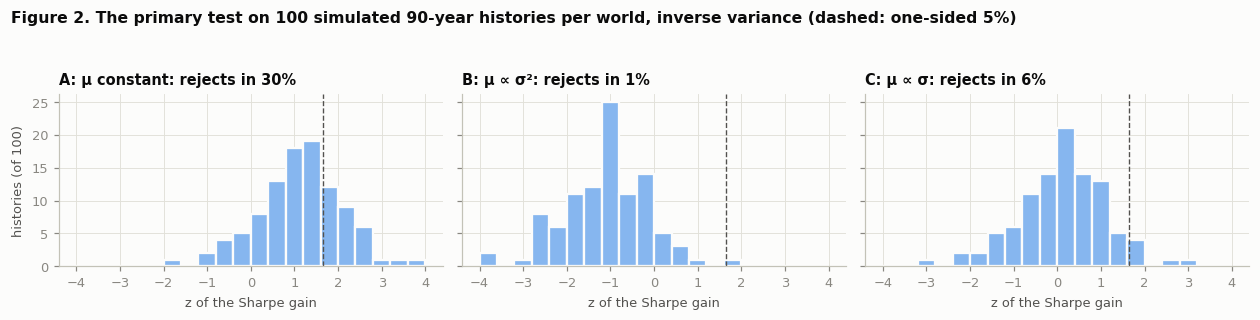

In [5]:
SEEDS, MC_YEARS = 100, 90                               # 100 histories as long as the real sample
mc = []
for seed in range(SEEDS):
    for w in syn.WORLDS:
        book = world(w, MC_YEARS, seed)
        for r in e.TIMING:
            res = e.run(book, r)
            t = ev.sharpe_gain_test(res)                    # the primary test
            mc.append({"seed": seed, "world": w, "rule": r, **row(res), "test z": t["z"],
                       "rejects": t["p"] < ev.TEST_RULES["level"], "mde": t["mde"], "reading": t["reading"]})
mc = pd.DataFrame(mc)

fig, axes = plt.subplots(1, 3, figsize=(11.5, 2.9), sharey=True)
crit = 1.6449                                            # one-sided 5%
bins = np.arange(-4, 4.01, 0.4)
for ax, w in zip(axes, ["flat", "var", "vol"]):
    z = mc.query("world == @w and rule == 'inv_var'")["test z"]
    ax.hist(z, bins=bins, color=LIGHT, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(crit, color=INK2, lw=0.9, ls="--")
    ax.set_title(f"{WORLD_NAMES[w]}: rejects in {(z > crit).mean():.0%}")
    ax.set_xlabel("z of the Sharpe gain")
axes[0].set_ylabel(f"histories (of {SEEDS})")
fig.suptitle(f"Figure 2. The primary test on {SEEDS} simulated {MC_YEARS}-year histories per world, inverse variance (dashed: one-sided 5%)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

g = mc.groupby(["world", "rule"])
power = pd.DataFrame({"mean Sharpe gain": g["Sharpe gain"].mean(), "primary test rejects": g["rejects"].mean(),
                      "MDE at 80% power": g["mde"].median(), "alpha: t > 1.96 (for comparison)": g["t_alpha"].apply(lambda s: (s > 1.96).mean()),
                      "share with a Sharpe gain": g["Sharpe gain"].apply(lambda s: (s > 0).mean())})
power = power.rename(index=WORLD_NAMES, level=0).rename(index=RULE_NAMES, level=1).loc[[WORLD_NAMES[w] for w in ["flat", "var", "vol"]]]
display(power.style.format({"mean Sharpe gain": "{:+.3f}", "primary test rejects": "{:.0%}", "MDE at 80% power": "{:.3f}",
                            "alpha: t > 1.96 (for comparison)": "{:.0%}", "share with a Sharpe gain": "{:.0%}"}))
readings = pd.crosstab(mc.query("rule == 'inv_var'")["world"], mc.query("rule == 'inv_var'")["reading"], normalize="index")
print("Readings of the primary test, inverse variance, 90-year histories:")
display(readings.rename(index=WORLD_NAMES).loc[[WORLD_NAMES[w] for w in ["flat", "var", "vol"]], ["edge", "inconclusive", "no meaningful edge"]]
        .style.format("{:.0%}"))
best = mc.pivot_table(index=["world", "seed"], columns="rule", values="Sharpe gain").idxmax(axis=1).groupby(level=0).value_counts(normalize=True).unstack().fillna(0)
print("Share of histories in which each rule has the largest Sharpe gain:")
display(best.rename(index=WORLD_NAMES, columns=RULE_NAMES).style.format("{:.0%}"))


**Reading.**

- **The primary test is much weaker than the alpha test.** In world A, inverse-variance alpha reaches t > 1.96 in 70% of 90-year histories, but the Sharpe-gain test rejects in only 30%. Alpha asks whether the timed returns contain something buy-and-hold does not. The Sharpe gain asks whether that something is big enough to lift one noisy Sharpe ratio above another, and the two series are highly correlated. World A's true gain averages 0.09 a year; its standard error over 90 years is about 0.07.
- **Minimum detectable effect: 0.18 a year at 80% power over 90 years**, twice world A's gain. A gain this test can reliably see would be larger than anything these worlds produce.
- **Inverse variance, the primary rule, is the hardest to test.** Its minimum detectable effect (0.17–0.18) is about 50% larger than the volatility rules' (0.11–0.12), and in world A its test rejects least often (30%, against 40% and 48%). Leaning hardest on the forecast makes its timed returns track buy-and-hold less closely, which makes the gap between the two Sharpe ratios noisier.
- **The readings.** In world A: "edge" 30%, "inconclusive" 61%, "no meaningful edge" 9%. World A's true gain (0.09) is itself just below the 0.10 line, so "no meaningful edge" is not wrong there. In world B, where there is nothing to find: "no meaningful edge" 84% and "edge" 1%. The test's false-positive rate stays under its 5%.
- **The rules rank as theory says.** Inverse variance has the largest Sharpe gain most often in world A (54%), and inverse volatility in world C (52%). In world B inverse variance is the worst rule: its average Sharpe loss (−0.08) is three times the volatility rules' (−0.03), because it leans hardest.
- **Downside inverse volatility behaves like inverse volatility here.** That is expected: the simulated shocks are symmetric, so bad days carry no extra news. Wang and Yan's case for it rests on the real market's asymmetry (Phase 2, Test 3), which these worlds do not have.

### The holdout is shorter still

The final test (Phase 9) runs once, on the holdout: 92 months, January 2019 to August 2026. Below, the same test on 200 simulated windows of that length per world. Each window follows ten years of history, so $c_t$ is built exactly as it would be in real time.

In [6]:
HOLDOUT_MONTHS, DRAWS = 92, 200                          # 2019-01 to 2026-08, the sealed holdout's length
hp = []
for seed in range(DRAWS):
    for w in ["flat", "var"]:
        res = e.run(world(w, 10 + HOLDOUT_MONTHS / 12 + 1.5, seed)).iloc[-HOLDOUT_MONTHS:]   # 10 years to build c_t first
        t = ev.sharpe_gain_test(res)
        hp.append({"world": WORLD_NAMES[w], "months": len(res), "rejects": t["p"] < ev.TEST_RULES["level"], "gain": t["gain"],
                   "standard error": t["se"], "mde": t["mde"], "reading": t["reading"]})
hp = pd.DataFrame(hp)
g = hp.groupby("world")
tab = pd.DataFrame({"months": g["months"].min(), "mean Sharpe gain": g["gain"].mean(), "standard error": g["standard error"].median(),
                    "MDE at 80% power": g["mde"].median(), "primary test rejects": g["rejects"].mean()})
tab = tab.join(pd.crosstab(hp["world"], hp["reading"], normalize="index")[["edge", "inconclusive", "no meaningful edge"]])
display(tab.style.format({"months": "{:.0f}", "mean Sharpe gain": "{:+.3f}", "standard error": "{:.3f}", "MDE at 80% power": "{:.2f}",
                          "primary test rejects": "{:.0%}", "edge": "{:.0%}", "inconclusive": "{:.0%}", "no meaningful edge": "{:.0%}"}))


,months,mean Sharpe gain,standard error,MDE at 80% power,primary test rejects,edge,inconclusive,no meaningful edge
world,,,,,,,,
A: μ constant,92,+0.074,0.187,0.46,10%,10%,83%,7%
B: μ ∝ σ²,92,-0.063,0.186,0.46,4%,4%,73%,24%


**Reading.** On a holdout-length window, the standard error of the Sharpe gain is about 0.19 a year, and the minimum detectable effect at 80% power is 0.46. The test rejects in 10% of world-A windows and 4% of world-B windows. 83% of world-A readings and 73% of world-B readings are "inconclusive", because a 95% upper bound below 0.10 needs a gain of about −0.21 or worse. So the final test on the holdout alone can call an edge only if it is very large, and can rule one out only if timing clearly loses. That is what the minimum detectable effect will report beside the result.

**Means.** The engine finds the edge in world A, finds none in world B, and ranks the rules as theory predicts. The primary test is honest, rejecting about 5% of the time or less when there is nothing, but its power is low at 90 years and lower still at 92 months. The three readings keep a non-rejection from being read as "no edge".

## 5. Check 2 — A constant forecast

**What and why.** It confirms the zero-alpha case of the math. If $\hat\sigma_t^2$ never changes, the size never changes, so the timed account is buy-and-hold scaled by a constant, and its alpha must be zero to floating point.

**Rule.** World A, costs off, forecast fixed at 0.002. (a) With the real-time $c_t$: $c_t = \mathrm{sd}(r)/\mathrm{sd}(r \times s) = 1/s$, so the size is exactly 1 and the timed account equals buy-and-hold. (b) With a fixed $c$ that makes the size 0.7: timed = 0.7 × buy-and-hold every month, α = 0, β = 0.7, R² = 1.

In [7]:
A = world("flat")
const = fc.constant(0.002)
rt = e.run(A, forecaster=const)                            # real-time c_t
fixed = e.run(A, forecaster=const, c=0.7 * 0.002)          # a fixed c that makes the size 0.7
rows = {}
for name, res in (("real-time c_t", rt), ("fixed c, size 0.7", fixed)):
    sp = ev.spanning(res["excess"], res["bench_excess"])
    target = res["size"].iloc[0]
    rows[name] = {"size: min": res["size"].min(), "size: max": res["size"].max(), "alpha a year": sp["alpha"], "beta": sp["beta"], "R²": sp["r2"],
                  "largest |timed - size x buy-and-hold|": (res["excess"] - target * res["bench_excess"]).abs().max(),
                  "Sharpe: timed": ev.sharpe(res["excess"]), "Sharpe: buy-and-hold": ev.sharpe(res["bench_excess"])}
display(pd.DataFrame(rows).T.style.format({"size: min": "{:.12f}", "size: max": "{:.12f}", "alpha a year": "{:.1e}", "beta": "{:.12f}",
                                           "R²": "{:.12f}", "largest |timed - size x buy-and-hold|": "{:.1e}", "Sharpe: timed": "{:.6f}", "Sharpe: buy-and-hold": "{:.6f}"}))


,size: min,size: max,alpha a year,beta,R²,largest |timed - size x buy-and-hold|,Sharpe: timed,Sharpe: buy-and-hold
real-time c_t,1.000000000000,1.000000000000,-1.6e-16,1.000000000000,1.000000000000,4.2e-16,0.390006,0.390006
"fixed c, size 0.7",0.700000000000,0.700000000000,1.5e-16,0.700000000000,1.000000000000,1.8e-16,0.388355,0.388355


**Result: pass.** (a) The size is 1 to twelve decimals, and the timed and buy-and-hold accounts differ by at most 4 × 10⁻¹⁶ a month. (b) The size is 0.7, timed = 0.7 × buy-and-hold to 2 × 10⁻¹⁶, α is of order 10⁻¹⁶, β = 0.7 and R² = 1.

**Why (b) is exact even though the position drifts.** Holding 0.7 of an asset and 0.3 cash for a month earns $0.7R + 0.3R^f$, whose excess return is exactly $0.7(R - R^f)$. The drift is undone at each month-end (it costs turnover, which is why costs are off here), and nothing else touches the excess return. If the engine applied the size to the wrong month, or let the drift leak into the next month's return, this check would show it.

## 6. Check 3 — Shuffled forecasts (the placebo)

**What and why.** Real timing must beat random timing. Each of 1,000 draws takes the forecast values and reorders them at random in time, then reruns weights ($c_t$ included) and execution. A shuffled forecast has the same values, the same spread and the same extremes, but no link to the month it is used in. So its alphas show what timing earns by luck.

**Rule.** (a) The shuffled alphas are centered on zero: their mean is within a tenth of their standard deviation (this cutoff was set after the 3,000-draw run described below). (b) The placebo rule, a permutation test with no distribution assumptions: the real alpha must beat 95% of the shuffled alphas. It must pass in world A and fail in world B. On real data this rule is applied from Phase 6.

,real alpha,shuffled: mean,shuffled: median,shuffled: sd,mean / sd,mean / standard error,shuffled: 95th percentile,share the real alpha beats,placebo rule (beats 95%)
A: μ constant,+1.953%,+0.002%,-0.008%,+0.296%,+0.005,+0.17,+0.500%,100.0%,pass
B: μ ∝ σ²,+0.128%,-0.000%,+0.001%,+0.291%,-0.001,-0.02,+0.473%,67.2%,fail


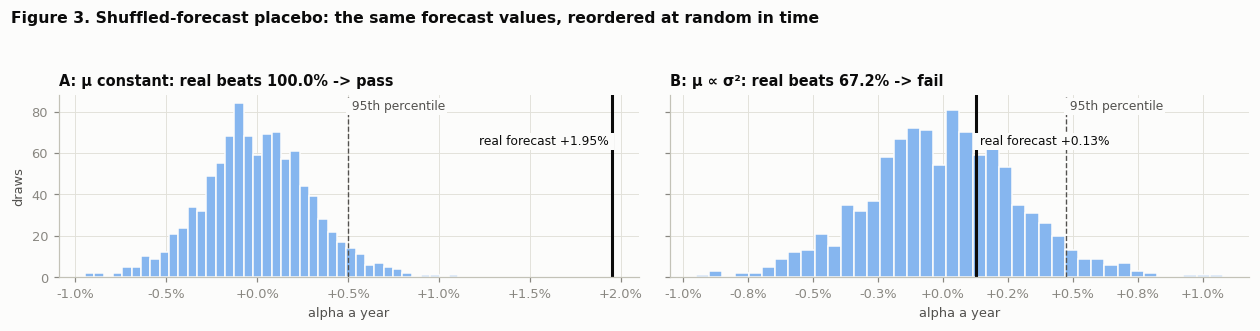

In [8]:
pl = {w: e.placebo(world(w), draws=e.ENGINE_RULES["placebo_draws"], seed=1) for w in ["flat", "var"]}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.0), sharey=True)
for ax, w in zip(axes, pl):
    s, real = pl[w]["shuffled"], pl[w]["alpha"]
    ax.hist(s, bins=40, color=LIGHT, edgecolor=SURFACE, linewidth=1.0, label="1,000 shuffled forecasts")
    q95 = np.quantile(s, 0.95)
    ax.axvline(q95, color=INK2, lw=0.9, ls="--")
    ax.axvline(real, color=INK, lw=2.0)
    top = ax.get_ylim()[1]
    box = dict(boxstyle="square,pad=0.15", fc=SURFACE, ec="none")
    ax.text(q95, top * 0.97, " 95th percentile", fontsize=8, color=INK2, va="top", bbox=box)
    right = real > q95                                          # label on the side away from the histogram
    ax.text(real, top * 0.78, f"real forecast {real:+.2%} " if right else f" real forecast {real:+.2%}", fontsize=8,
            color=INK, va="top", ha="right" if right else "left", bbox=box)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:+.1%}")
    ax.set_xlabel("alpha a year"); ax.set_title(f"{WORLD_NAMES[w]}: real beats {pl[w]['share_beaten']:.1%} -> {'pass' if pl[w]['pass'] else 'fail'}")
axes[0].set_ylabel("draws")
fig.suptitle("Figure 3. Shuffled-forecast placebo: the same forecast values, reordered at random in time", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

tab = pd.DataFrame({WORLD_NAMES[w]: {"real alpha": p["alpha"], "shuffled: mean": p["shuffled"].mean(), "shuffled: median": np.median(p["shuffled"]),
                                     "shuffled: sd": p["shuffled"].std(), "mean / sd": p["shuffled"].mean() / p["shuffled"].std(),
                                     "mean / standard error": p["shuffled"].mean() / (p["shuffled"].std() / np.sqrt(len(p["shuffled"]))),
                                     "shuffled: 95th percentile": np.quantile(p["shuffled"], 0.95), "share the real alpha beats": p["share_beaten"],
                                     "placebo rule (beats 95%)": "pass" if p["pass"] else "fail"} for w, p in pl.items()}).T
display(tab.style.format({c: "{:+.3%}" for c in ["real alpha", "shuffled: mean", "shuffled: median", "shuffled: sd", "shuffled: 95th percentile"]}
                         | {"mean / sd": "{:+.3f}", "mean / standard error": "{:+.2f}", "share the real alpha beats": "{:.1%}"}))


**Result: pass.** The shuffled alphas are centered on zero in both worlds: mean +0.002% a year in A and −0.000% in B, with a spread of about 0.30%. In world A the real alpha (+1.95%) beats all 1,000 and passes the placebo rule by a wide margin. In world B the real alpha (+0.13%) beats 67%: it looks like a lucky draw, and the rule rejects it.

**A tiny bias, measured.** With 3,000 draws instead of 1,000, the mean shuffled alpha in world A is +0.013% a year, 2.4 standard errors from zero. That is 1/150 of the real edge and 4% of the spread. Theory says exactly zero only for a fixed $c$ without a cap, and with that setup the mean is 1.2 standard errors from zero. The real-time $c_t$ and the cap leave a small second-order effect. It is far too small to matter for a test at the 95th percentile, which is why rule (a) is set relative to the spread.

**Why the placebo matters more than the t-stat.** A t-stat assumes the alphas are roughly normal. The placebo rule asks only whether the real ordering of forecasts beats random orderings of the same forecasts. That is exactly the question, and it holds whatever the distribution.

## 7. Check 4 — The oracle

**What and why.** Feed in next month's actual variance, $RV_{t+1}$, as if it were known in advance. No real forecast can do better than knowing the answer, so the oracle is a rough upper bound on what any forecast upgrade can add. If even the oracle barely beats the baseline, no forecast upgrade can save the strategy.

**Rule.** (a) In world A, Sharpe ratios rank buy-and-hold < baseline < oracle. (b) In world U, where each month's variance is drawn fresh so the past says nothing about it (`synthetic.unpredictable`), the baseline has no significant alpha (t < 1.96) and the oracle's Sharpe ratio beats buy-and-hold's by at least 0.1: a large jump. World U and its 0.1 threshold were added after a pilot showed that the GARCH worlds leave the oracle little to add (below). Across ten pilot seeds the capped jump was 0.11–0.19, so 0.1 has little slack.

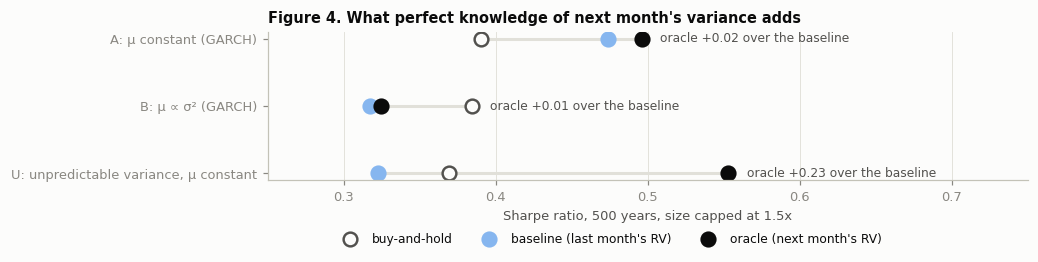

In [9]:
U = syn.unpredictable(years=YEARS, seed=0)
books = {"A: μ constant (GARCH)": world("flat"), "B: μ ∝ σ² (GARCH)": world("var"),
         "U: unpredictable variance, μ constant": e.Book.single(U["x"], U["rf"])}
orc = {}
for name, book in books.items():
    for cap in (e.ENGINE_RULES["max_size"], None):
        base, oracle = e.run(book, max_size=cap), e.run(book, forecaster=fc.oracle, max_size=cap)
        orc[(name, "1.5x cap" if cap else "no cap")] = {
            "buy-and-hold": ev.sharpe(base["bench_excess"]), "baseline (last month's RV)": ev.sharpe(base["excess"]),
            "oracle (next month's RV)": ev.sharpe(oracle["excess"]), "baseline alpha t": ev.spanning(base["excess"], base["bench_excess"])["t_alpha"],
            "oracle alpha t": ev.spanning(oracle["excess"], oracle["bench_excess"])["t_alpha"]}
orc = pd.DataFrame(orc).T
orc["oracle - baseline"] = orc["oracle (next month's RV)"] - orc["baseline (last month's RV)"]

fig, ax = plt.subplots(figsize=(9.5, 2.9))
capped = orc.xs("1.5x cap", level=1)
marks = {"buy-and-hold": dict(marker="o", mfc=SURFACE, mec=INK2), "baseline (last month's RV)": dict(marker="o", mfc=LIGHT, mec=LIGHT),
         "oracle (next month's RV)": dict(marker="o", mfc=INK, mec=INK)}
for i, (name, r) in enumerate(capped.iterrows()):
    ax.plot([r[list(marks)].min(), r[list(marks)].max()], [i, i], color=GRID, lw=2, zorder=1)
    for k, m in marks.items():
        ax.plot(r[k], i, ms=9, mew=1.6, ls="", zorder=2, **m)
    ax.text(r[list(marks)].max() + 0.012, i, f"oracle {r['oracle - baseline']:+.2f} over the baseline", va="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(capped)), capped.index); ax.invert_yaxis(); ax.set_xlim(0.25, 0.75)
ax.set_xlabel(f"Sharpe ratio, {YEARS} years, size capped at 1.5x"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Line2D([], [], ls="", ms=9, mew=1.6, label=k, **m) for k, m in marks.items()], loc="lower center",
          bbox_to_anchor=(0.45, -0.52), ncol=3, fontsize=8)
ax.set_title("Figure 4. What perfect knowledge of next month's variance adds")
fig.tight_layout()
display(orc.style.format("{:.3f}").format({"baseline alpha t": "{:+.2f}", "oracle alpha t": "{:+.2f}", "oracle - baseline": "{:+.3f}"}))


**Result: pass.** In world A, buy-and-hold 0.39 < baseline 0.47 < oracle 0.50. In world U the baseline's alpha has t = 1.2, and the oracle beats buy-and-hold by 0.18 (0.37 to 0.55).

**Reading: the gap between the oracle and the baseline is the room a forecast has to win.**

- **GARCH world A: +0.02** (capped) or +0.04 (uncapped). With smooth, persistent variance, last month's RV already tracks next month's variance well, so perfect knowledge adds little. A better forecast model would add even less.
- **World U: +0.23.** The past says nothing, so the baseline cannot time at all. Its Sharpe ratio actually falls (0.37 to 0.32): it resizes on noise, which adds risk and no return. The oracle, which sees the answer, jumps.
- **World B: +0.007.** When timing cannot help, knowing the future does not help either. The oracle's alpha t is only 0.6.

**For Phase 6.** On real data, the oracle-minus-baseline gap is the first number to read. A small gap means last month's RV is close to the best a forecast can do, so any gain from a better model will be small. A large gap means forecasting is where the gains are.

## 8. Check 5 — The hand check

**What and why.** It catches off-by-one indexing bugs. `reports/phase5_hand_check.xlsx` holds two years of simulated daily returns for two instruments, A and B, and rebuilds every step of the engine with plain spreadsheet formulas, one column per step. Monthly RV of the mix under each recipe, the signal, $c_t$ as `STDEV` over an expanding range, the capped size, the positions, drift, turnover, trading cost, borrowing, the short fee, net and excess returns, for the timed book and for buy-and-hold. Open it in Excel or Numbers to follow any cell.

**The case exercises every part of the engine.** Two recipes, one per year. Recipe 1 holds 0.8 A + 0.6 B, so it borrows cash at sizes above 0.71; recipe 2 holds −0.3 A + 1.2 B, so A is short and pays the fee. The cap is 1.3, so it binds. $c_t$ needs only 6 pairs, so two years are enough. κ is 5 bp for A and 10 bp for B, with a 0.5% borrow spread, a 0.25% short fee and a rising risk-free rate. The calendar skips the 2016–2017 exchange holidays.

**Five months**, chosen where indexing goes wrong: 2016-08 (the first month with a size, an entry trade from cash, capped and borrowing), 2016-10 (below the cap, no borrowing), 2016-12 (the last month of recipe 1, capped), 2017-01 (the recipe changes: the size uses December under the new recipe, and A turns short), 2017-12 (the last month).

**Rule.** All 70 numbers (14 quantities × 5 months) match: a relative gap below 10⁻¹¹. The workbook's formula values were computed by the `formulas` package (an Excel formula engine) when it was built (`python -m src.engine.handcheck`), and `test_5_hand_check_matches_the_spreadsheet` compares them with a fresh engine run.

In [10]:
daily, check = hc.read()                                    # the workbook as stored: its inputs and its formula values
res = hc.engine_run(daily)                                  # a fresh engine run on the workbook's inputs
check["engine (now)"] = [res.loc[pd.Period(m, "M"), q] for m, q in zip(check["month"], check["quantity"])]
check["difference (now)"] = check["engine (now)"] - check["spreadsheet"]
wide = check.pivot(index="quantity", columns="month", values="spreadsheet").loc[hc.QUANTITIES]
print("Spreadsheet values at the five check months (each recomputed from the daily inputs with plain formulas):")
display(wide.style.format("{:.6f}"))
print(f"Largest |engine - spreadsheet| over {len(check)} numbers: {check['difference (now)'].abs().max():.1e}")


Spreadsheet values at the five check months (each recomputed from the daily inputs with plain formulas):


month,2016-08,2016-10,2016-12,2017-01,2017-12
quantity,,,,,
forecast,0.001136,0.002571,0.000773,0.001834,0.001191
c,0.002172,0.001708,0.001926,0.002306,0.001292
size,1.300000,0.664283,1.300000,1.257554,1.084991
w_A,1.040000,0.531426,1.040000,-0.377266,-0.325497
w_B,0.780000,0.398570,0.780000,1.509064,1.301989
drift_A,1.073947,0.506762,0.997534,-0.382935,-0.324082
drift_B,0.807341,0.419362,0.757082,1.513659,1.300493
turnover,1.820000,0.289470,0.038894,2.126782,0.163977
trading,0.001300,0.000200,0.000035,0.001439,0.000149


Largest |engine - spreadsheet| over 70 numbers: 2.1e-14


**Result: pass.** The largest gap over 70 numbers is 2 × 10⁻¹⁴: floating point, not a difference in method.

### Does the check bite?

A check that has never failed proves little. Below, one bug at a time is planted in the engine, the engine is rerun on the workbook's inputs, and the largest gap from the spreadsheet is measured. "Month missing" means the engine no longer produced one of the five months at all.

In [11]:
# Plant a bug, rerun the engine on the workbook's inputs, and measure the largest gap from the spreadsheet.
def gap(run=hc.engine_run):
    res = run(daily)
    eng = np.array([res[q].get(pd.Period(m, "M"), np.nan) for m, q in zip(check["month"], check["quantity"])], dtype=float)
    return np.nanmax(np.abs(eng - check["spreadsheet"].to_numpy(float))) if not np.isnan(eng).any() else np.inf

import src.engine as eng_mod
def planted(target, name, fake):
    old = getattr(target, name); setattr(target, name, fake)
    try:
        return gap()
    finally:
        setattr(target, name, old)

real_c, real_decide, real_prepare, real_periods = wt.realtime_c, e.decide, e.prepare, ex.holding_periods
def lagless(*a, **k):
    d = real_decide(*a, **k); cols = ["forecast", "signal", "c", "size", "capped"]; d[cols] = d[cols].shift(-1); return d.iloc[:-1]
def old_recipe(book, f):
    p = real_prepare(book, f); p[1] = p[1].assign(forecast=p[0]["forecast"]); return p
ns = dict(vars(ex))
exec(compile(Path(ex.__file__).read_text().replace("before = drift.shift(1).fillna(0.0)", "before = w.shift(1).fillna(0.0)"), "planted", "exec"), ns)

bugs = {
    "none (the engine as built)": gap(),
    "c_t uses the pair completed a month later": planted(wt, "realtime_c", lambda *a, **k: real_c(*a, **k).shift(-1)),
    "size used in the month it is decided (no lag)": planted(eng_mod, "decide", lagless),
    "drift ignored (trade measured from the old target)": planted(ex, "simulate", ns["simulate"]),
    "traded one day after month-end": planted(ex, "holding_periods", lambda book, costs=ex.NO_COSTS, delay=0: real_periods(book, costs, 1)),
    "January sized on the old recipe's mix": planted(eng_mod, "prepare", old_recipe),
    "financing dropped": gap(lambda d: hc.engine_run(d, dict(hc.PARAMS, borrow_spread=0.0, short_fee_A=0.0))),
    "c_t needs 7 pairs instead of 6": gap(lambda d: hc.engine_run(d, dict(hc.PARAMS, min_months=7))),
}
display(pd.DataFrame({"largest gap from the spreadsheet": bugs}).style.format(lambda x: "month missing" if np.isinf(x) else f"{x:.1e}"))


,largest gap from the spreadsheet
none (the engine as built),2.1e-14
c_t uses the pair completed a month later,1.8e+00
size used in the month it is decided (no lag),month missing
drift ignored (trade measured from the old target),3.9e-02
traded one day after month-end,2.1e-02
January sized on the old recipe's mix,6.3e-01
financing dropped,4.3e-04
c_t needs 7 pairs instead of 6,month missing


**Reading.** Every planted bug moves at least one number by 4 × 10⁻⁴ or more, against 2 × 10⁻¹⁴ for the clean engine. The smallest, dropping financing, is still 20 billion times the clean gap. The bugs cover each place the plan's checks are meant to guard: the one-month lag (twice), the pairing inside $c_t$, the recipe change, drift, execution timing, and costs.

**Means.** The five checks pass, and the hand check is shown to catch the bugs it exists for. The engine is verified.

## 9. Real-time $c_t$ and the cap

**What and why.** The plan warns that with a fixed $c$ the Sharpe ratio ignores $c$, but that in real time $c_t$ drifts and meets the cap, so it changes results. Both halves can be checked on simulated data. World A, one 90-year history, inverse variance, costs off. Information, not a check.

,months,Sharpe: timed,Sharpe: buy-and-hold,volatility: timed,volatility: buy-and-hold
"full-sample c, no cap (Moreira and Muir)",1043,0.530,0.527,14.8%,14.8%
"full-sample c, 1.5x cap",1043,0.566,0.527,11.9%,14.8%
"real-time c_t, no cap",923,0.588,0.559,16.5%,14.6%
"real-time c_t, 1.5x cap (the primary)",923,0.630,0.559,12.7%,14.6%
"full-sample c x 2, no cap",1043,0.530,0.527,29.7%,14.8%
"full-sample c x 2, 1.5x cap",1043,0.589,0.527,16.3%,14.8%


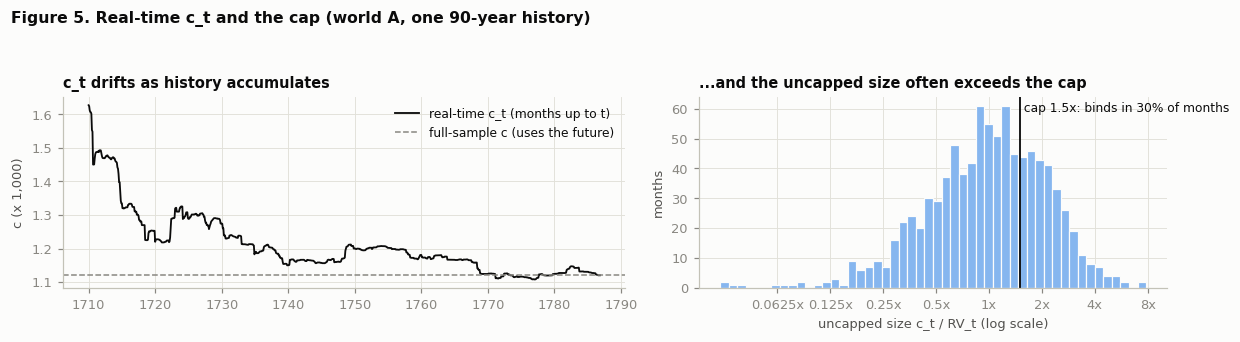

In [12]:
A90 = world("flat", 90)
mon = e.prepare(A90, fc.last_rv)[0]
sig = wt.signal(mon["forecast"], 1.0)
c_rt = wt.realtime_c(mon["ret"], sig, e.ENGINE_RULES["min_months"])
nxt = mon["ret"].shift(-1)
c_full = nxt.std() / (nxt * sig).std()                    # Moreira and Muir: the whole sample, future included

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.1), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.plot(c_rt.index.to_timestamp(), c_rt * 1e3, color=INK, lw=1.2, label="real-time c_t (months up to t)")
ax.axhline(c_full * 1e3, color=MUTED, lw=1.0, ls="--", label="full-sample c (uses the future)")
ax.set_ylabel("c (x 1,000)"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("c_t drifts as history accumulates")
ax = axes[1]
res = e.run(A90)
size = res["size"]; raw = res["c"] * res["signal"]
ax.hist(np.log2(raw), bins=50, color=LIGHT, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(np.log2(1.5), color=INK, lw=1.2)
ax.text(np.log2(1.5), ax.get_ylim()[1] * 0.92, f" cap 1.5x: binds in {res['capped'].mean():.0%} of months", fontsize=8)
ax.set_xticks(np.arange(-4, 4), [f"{2.0 ** k:g}x" for k in range(-4, 4)]); ax.set_xlabel("uncapped size c_t / RV_t (log scale)")
ax.set_ylabel("months"); ax.set_title("...and the uncapped size often exceeds the cap")
fig.suptitle("Figure 5. Real-time c_t and the cap (world A, one 90-year history)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

variants = {"full-sample c, no cap (Moreira and Muir)": dict(c=c_full, max_size=None), "full-sample c, 1.5x cap": dict(c=c_full),
            "real-time c_t, no cap": dict(max_size=None), "real-time c_t, 1.5x cap (the primary)": {},
            "full-sample c x 2, no cap": dict(c=2 * c_full, max_size=None), "full-sample c x 2, 1.5x cap": dict(c=2 * c_full)}
out = {}
for k, o in variants.items():
    r = e.run(A90, **o)
    out[k] = {"months": len(r), "Sharpe: timed": ev.sharpe(r["excess"]), "Sharpe: buy-and-hold": ev.sharpe(r["bench_excess"]),
              "volatility: timed": r["excess"].std() * np.sqrt(12), "volatility: buy-and-hold": r["bench_excess"].std() * np.sqrt(12)}
display(pd.DataFrame(out).T.style.format({"months": "{:.0f}", "Sharpe: timed": "{:.3f}", "Sharpe: buy-and-hold": "{:.3f}",
                                          "volatility: timed": "{:.1%}", "volatility: buy-and-hold": "{:.1%}"}))


**Reading.**

- **A fixed $c$ without a cap: the Sharpe ratio ignores $c$.** Doubling it doubles the volatility (14.8% to 29.7%) and leaves the Sharpe ratio at 0.530. That is the plan's statement, and `test_with_a_fixed_c_and_no_cap_the_sharpe_ratio_ignores_c` checks it exactly.
- **With the cap, $c$ matters.** The same doubling changes the capped Sharpe ratio from 0.566 to 0.589, because a larger $c$ pushes more months into the cap.
- **$c_t$ drifts.** It starts 45% above the full-sample value and takes about 60 years to settle, because early history is short and noisy. Every early decision runs on a different $c$ than hindsight would pick. On the real data, where variance levels drift across eras (Phase 2), the effect may be larger.
- **The cap binds in 30% of months** in this history, and it raises the Sharpe ratio here (0.588 to 0.630 in real time), as it did for the real primary in Phase 4. The sizes above 1.5× follow calm months, when the forecast is low and the next month is often not calm.
- **Different samples.** The real-time rows start 120 months later than the full-sample rows (923 against 1,043 months), so their buy-and-hold Sharpe ratios differ too. Compare within a row.

## 10. Costs and break-even (mechanics only)

**What and why.** The paper factors are before costs. The ETF track pays κ on every resize, borrows when the size passes 1, and pays a fee on its SPY short. Cost guesses are shaky, so the plan reports the break-even κ as the safety margin.

**Two kinds of break-even, both reported.** The first is the κ at which the timed Sharpe ratio falls to buy-and-hold's, with both paying κ on their own turnover. The second is the κ that wipes out each strategy's profit (`zero_profit_cost`). A round trip is 2κ. Neither is compared with Barroso and Santa-Clara's 1.27 and 1.75 points: those are the costs that make momentum's profits insignificant at 5%, and they appear to include the trading inside the factor, which the engine does not price.

Here world A is traded as if it were SPY: κ = 5 bp, borrowing at rf + 0.5%. One 90-year history; information, not a check.

In [13]:
spy_costs = e.Costs(kappa={"asset": 5e-4}, borrow_spread=0.005)     # world A traded like SPY
book = world("flat", 90)
rows = {}
for r in e.TIMING:
    gross, net = e.run(book, r), e.run(book, r, costs=spy_costs)
    k = ev.break_even(gross)
    rows[RULE_NAMES[r]] = {"turnover a year": gross["turnover"].iloc[1:].mean() * 12,
                           "buy-and-hold turnover a year": gross["bench_turnover"].iloc[1:].mean() * 12,
                           "trading cost a year": net["trading"].iloc[1:].mean() * 12, "borrowing cost a year": net["financing"].mean() * 12,
                           "Sharpe gain before costs": ev.sharpe(gross["excess"]) - ev.sharpe(gross["bench_excess"]),
                           "Sharpe gain after costs": ev.sharpe(net["excess"]) - ev.sharpe(net["bench_excess"]),
                           "break-even κ, one-way": k, "break-even, round trip": 2 * k,
                           "zero-profit κ, one-way": ev.zero_profit_cost(gross)}
display(pd.DataFrame(rows).T.style.format({"turnover a year": "{:.2f}", "buy-and-hold turnover a year": "{:.2f}", "trading cost a year": "{:.3%}",
                                           "borrowing cost a year": "{:.3%}", "Sharpe gain before costs": "{:+.3f}", "Sharpe gain after costs": "{:+.3f}",
                                           "break-even κ, one-way": "{:.2%}", "break-even, round trip": "{:.2%}", "zero-profit κ, one-way": "{:.2%}"}))


,turnover a year,buy-and-hold turnover a year,trading cost a year,borrowing cost a year,Sharpe gain before costs,Sharpe gain after costs,"break-even κ, one-way","break-even, round trip","zero-profit κ, one-way"
Inverse variance,3.32,0.00,0.166%,0.103%,+0.071,+0.050,0.27%,0.53%,2.38%
Inverse volatility,2.35,0.00,0.118%,0.112%,+0.079,+0.063,0.48%,0.96%,3.89%
Downside inverse vol,2.94,0.00,0.147%,0.107%,+0.118,+0.100,0.57%,1.13%,3.23%


**Reading.**

- **Inverse variance trades the most**: 3.3 times the account a year. It pays 0.17% a year to trade and 0.10% to borrow in the months above 1×, which cuts its Sharpe gain from +0.071 to +0.050.
- **Break-even: 0.27% one-way (0.53% round trip)**, five times the assumed 5 bp for SPY. The margin is comfortable for SPY, but it is a margin on a simulated edge. Real-data break-evens come in Phase 6.
- **The volatility rules trade less** (2.4 and 2.9 times a year), so their break-evens are higher (0.48% and 0.57% one-way). This is Wang and Yan's argument for volatility scaling.
- **Buy-and-hold of one asset never trades after its entry.** A mix does, because its pieces drift apart: the buy-and-hold mix pays to rebalance to its recipe each month, and the timed mix pays that too.
- **What the paper track's break-even measures.** The engine prices resizing the mix, not the trading inside each factor (a momentum portfolio turns over its stocks every month). For the paper track the break-even is the cost of timing alone; the cost of holding the factors is extra. That is why the average size is reported: the cost inside a factor scales with how much of it is held.

## 11. The engine on the real panel: mechanics only

**What and why.** The engine has to run on the real data in Phase 6. This checks that it does, on two books. The first is the Phase 4 primary book (the paper track's inverse-volatility mix, one recipe per year-end); here everything after 1990-06-15 is overwritten with noise, and every row up to May 1990, plus June 1990's decision, must be unchanged. The second is the ETF book (SPY + MTUM tilt), with its cost model and the 36-month rule for $c_t$. Only structure and look-ahead are checked. **No return, Sharpe ratio or alpha is computed for display**, and each result frame is deleted after its checks.

In [14]:
from src import portfolio as pf
from src.data.load import load_dev
panel = load_dev()
rec = pf.recipes(panel, "paper")
book = e.data.from_phase4(panel, rec, pf.PRIMARY[1])     # the Phase 4 primary: paper track, inverse-volatility mix
res = e.run(book)                                        # computed for the checks below; no return statistic is shown

cut = pd.Timestamp("1990-06-15")
noisy = panel.copy()
noisy.loc[noisy.index > cut, ["mkt", "mom", "bab"]] = np.random.default_rng(0).normal(0, 0.05, ((noisy.index > cut).sum(), 3))
res2 = e.run(e.data.from_phase4(noisy, rec, pf.PRIMARY[1]))      # same recipes, so this tests the engine alone
decision = ["recipe", "forecast", "signal", "c", "size", "capped"]
checks = {
    "instruments": ", ".join(book.returns.columns),
    "recipes (one per year-end)": e.data.recipe_ids(book.positions).nunique(),
    "holding months": f"{res.index[0]} to {res.index[-1]} ({len(res)})",
    "every month has a size": bool(res["size"].notna().all()),
    "size within [0, 1.5]": bool(res["size"].between(0, e.ENGINE_RULES["max_size"]).all()),
    "no missing value in any column": bool(res.notna().all().all()),
    "buy-and-hold holds the recipe at size 1": bool(np.allclose(res[[f"bench_w_{a}" for a in book.positions]], book.positions.loc[res.index])),
    "rows to May 1990 unchanged after rewriting all data after 1990-06-15": res.loc[:"1990-05"].equals(res2.loc[:"1990-05"]),
    "June 1990 decision unchanged": res.loc["1990-06", decision].equals(res2.loc["1990-06", decision]),
}
display(pd.DataFrame({"primary book (paper)": checks}).astype(str))
del res, res2                                            # Phase 6 reads the results

etf = e.data.from_phase4(panel, pf.recipes(panel, "etf"), pf.PRIMARY[1])   # SPY + MTUM tilt, with its costs
res = e.run(etf, min_months=e.ENGINE_RULES["etf_min_months"], costs=e.COSTS["etf"])
checks = {
    "instruments": ", ".join(etf.returns.columns),
    "holding months (c_t from 36 months)": f"{res.index[0]} to {res.index[-1]} ({len(res)})",
    "size within [0, 1.5]": bool(res["size"].between(0, e.ENGINE_RULES["max_size"]).all()),
    "no missing value in any column": bool(res.notna().all().all()),
    "SPY held short in every month": bool((res["w_spy"] < 0).all()),
    "short fee and borrowing charged in every month": bool((res["financing"] > 0).all()),
    "trading cost charged in every month": bool((res["trading"] > 0).all()),
}
display(pd.DataFrame({"ETF book": checks}).astype(str))
del res


,primary book (paper)
instruments,"mkt, mom, bab"
recipes (one per year-end),78
holding months,1941-01 to 2018-12 (936)
every month has a size,True
"size within [0, 1.5]",True
no missing value in any column,True
buy-and-hold holds the recipe at size 1,True
rows to May 1990 unchanged after rewriting all data after 1990-06-15,True
June 1990 decision unchanged,True


,ETF book
instruments,"spy, mtum"
holding months (c_t from 36 months),2016-06 to 2018-12 (31)
"size within [0, 1.5]",True
no missing value in any column,True
SPY held short in every month,True
short fee and borrowing charged in every month,True
trading cost charged in every month,True


**Result.** The engine runs on the real panel: 78 recipes, 936 holding months from January 1941 to December 2018, every size within [0, 1.5], no missing values. Rewriting all data after 15 June 1990 changes nothing before it. The 120 pairs $c_t$ needs come from the 1940 recipe applied to the mix's history since December 1930, when BAB starts. So the timed primary starts in January 1941, the same month as Phase 4's.

The ETF book is timed from June 2016: MTUM starts in April 2013, and $c_t$ needs 36 months. That gives 31 months to the end of the development sample, with SPY short and the fee, borrowing and trading costs charged in every month. Under the 120-month rule it would have had none.

## 12. Using the engine

```python
from src import engine as e
from src import portfolio as pf
from src.data.load import load_dev

panel = load_dev()
book = e.data.from_phase4(panel, pf.recipes(panel, "paper"), "inv_vol")   # the primary book
res = e.run(book, "inv_var")                        # one row per holding month (Phase 6 reads it)
e.run(book, "inv_vol"); e.run(book, "down_vol")     # the other two rules
e.run(book, forecaster=my_model)                    # Phase 6: a new forecast plugs in here
e.run(book, max_size=1.0)                           # Phase 8: caps 1.0 and 2.0; delay=1 trades a day late
e.run(etf_book, min_months=e.ENGINE_RULES["etf_min_months"], costs=e.COSTS["etf"])   # the ETF track
e.evaluation.sharpe_gain_test(res)                  # the primary test: gain, bounds, reading, MDE, volatilities, size
e.evaluation.summary(res); e.evaluation.spanning(res["excess"], res["bench_excess"])
e.evaluation.break_even(res)                        # one-way κ that erases the Sharpe gain
e.placebo(book, "inv_var")                          # real alpha vs 1,000 shuffled forecasts; ["pass"]

# Phase 6 opens by replicating the published single-factor results only, e.g. Barroso and Santa-Clara's
# momentum (Sharpe 0.53 -> 0.97, 1927-2011): 126-day variance, fixed 12% target, no cap
e.run(e.Book.single(panel["mom"], panel["rf"]), "inv_vol", forecaster=e.forecast.rv_days(126),
      c=e.weights.target_c(0.12), max_size=None)
```

`run` columns: the decision (`recipe`, `forecast`, `signal`, `c`, `size`, `capped`), the timed account (`gross`, `financing`, `pre_trade`, `turnover`, `trading`, `net`, `rf`, `excess`, and `w_<i>`, `drift_<i>` per instrument), and the same for buy-and-hold with the prefix `bench_`.

**Tests.** `python -m pytest` runs `test/test_engine.py` (each stage alone, plus the pipeline: look-ahead, January's recipe, the benchmark, the fixed-$c$ invariance, plugging in a forecaster) and `test/test_engine_checks.py` (the five checks of this notebook, 1,000 placebo draws included). The full suite runs in about 15 seconds.